# Using N-BEATS to Model Games Played per Level per Season (International League 2026 cohort)

In this notebook, I do the following:
- Access the MLB API to assemble a dataset consisting of all position players on International League rosters at the time of initial notebook execution (late October 2026).
- For each player, retrieve his minor league and major league game logs for each season from 2021-2026, then represent each season as a six-value vector recording the number of games in which he played at each level of affiliated baseball (rookie, low A, high A, AA, AAA, MLB).
- Use a version of the generic form of the N-BEATS architecture to train a model to project future values of this vector, taking past values as an input.
- In this initial example, I use a lookback of 2 seasons and a horizon of 1 season. This allows the data to be split relatively cleanly with two training windows (predicting 2023 given 2022 and 2021 and predicting 2024 and 2023 and 2022), one validation window (predicting 2025), and one testing window (predicting 2026).
- Finally, to help better understand the model's functioning, I build two visualizers. The first chooses a random International League player from our dataset, charting the distribution of his games-played/level vector for each of his seasons from 2021-2026 alongside our model's predicted values for his 2023-2026 seasons (using the prior two seasons as input). Then, as an early check on how well the model generalizes, I recreate the same visualization code, but this time using a randomly chosen player from the *Pacific* League--the other AAA league, which was not a part of the model's original training data.

Outstanding issues include:
- This dataset is skewed by survivorship bias: reaching AAA at all is not a given, and selects for certain career arcs. A more rigorous approach would 'intercept' players as they enter the affiliated leagues and follow them until they drop out of affiliated baseball. I don't currently know a convenient way to achieve this via the MLB API but it's probably solveable.
- Is N-BEATS the optimal architecture for this investigation? If not, what is?
- My values for lookback and horizon are constrained by: a) there was no minor league season in 2020 and b) the minor leagues contracted before the 2021 season. An outstanding question is: if I were to train a model on, say, 2005-2019 patterns, how different would it be? Would those patterns still be predictive?
- How should I handle the entry into affiliated ball point? Full double-zero inputs are problematic and uninformative, but a full zero leading into a non-zero vector would be potentially predictable. Perhaps I could screen for that.
- Finally, I potentially want to generalize out to models that include some additional features such as: birth year (translated to age at season); position(s) played, perhaps expressed as a percentage, with an especial attention to how pitchers require different modeling... AND perhaps I want an axis for Major League affiliation? For descriptive if not predictive purposes?

In [1]:
# Import statements:
import requests
import pandas as pd
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import torch
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import random
import matplotlib.gridspec as gridspec
import json

## Hardcoded API keys

I assembled the following API keys via manual navigation of https://statsapi.mlb.com/api/v1/ subdirectories. Aggregating league ids by level in lists such as `aaa_ids = [117, 112]` allows me to parse

In [2]:
# hardcoded api keys:
intl_league_id = 117
pcl_league_id = 112
aaa_ids = [117, 112]

eastern_league_id = 113
southern_league_id = 111
texas_league_id = 109
aa_ids = [113, 111, 109]

midwest_league_id = 118
sally_league_id = 116 
# Fun fact: id 148 returns a DIFFERENT south atlantic league
# (which most recent played 1963)
northwest_league_id = 126
high_a_ids = [118, 116, 126]

carolina_league_id = 122
florida_state_league_id = 123
california_league_id = 110
low_a_ids = [122, 123, 110]

az_complex_league_id = 121
fl_complex_league_id = 123
dsl_league_id = 130
rookie_ids = [121, 123, 130]

## Data Access & Preparation
I am indebted to the work of Ben-Ohr Brill (<https://benohrbrill.com/data/milb/>) throughout this section. He published the code of his study on the impact of minor league injuries on future MLB playing time, which provided me a model for how to work with the MLB API in Python code.

### Helper functions:

In [3]:
# Data access and processing helper functions

def get_league_team_ids(team_dict, league_id):
    """ In: the dictionary of all teams and a league's id
        Out: a list of the ids of all teams in that league """
    print(f'Fetching list of teams in league {league_id}:')
    print('----------------------------------------------')
    team_id_list = []
    for team in team_dict['teams']:
        if 'id' in team['league'] and team['league']['id'] == league_id:
            print(team['name'])
            team_id_list.append(team['id'])
    return team_id_list

def get_team_roster_hitter_ids(team_id):
    """ In: a team's id
        Out: a list of the ids of all hitters on that team's current roster """
    roster = requests.get(f'https://statsapi.mlb.com/api/v1/teams/{team_id}/roster').json()
    player_id_list = []
    #print(roster['roster'])
    for player in roster['roster']:
        if player['position']['code'] != '1':
            print(f'{player['person']['id']}  {player['person']['fullName']} {player['position']}')
            player_id_list.append(player['person']['id'])
    return player_id_list

def get_hitter_minor_logs(player_id, season):
    """ Fetch all minor league hitting stat logs for given player and season """
    return requests.get(f"https://statsapi.mlb.com/api/v1/people/{player_id}/stats?stats=gameLog&gameType=R&leagueListId=milb_all&group=hitting&hydrate=team(league)&language=en&season={season}",).json()

def get_hitter_major_logs(player_id, season):
    """ Fetch all major league hitting stat logs for given player and season """
    return requests.get(f'https://statsapi.mlb.com/api/v1/people/{player_id}/stats?season={season}&group=hitting&stats=gameLog',).json()

def game_count_by_level(minor_logs, major_logs):
    """ In: dicts of all minor league and major league game logs for a given player & season
        Out: a six-value vector of integers of form: <R, lo_A, hi_A, AA, AAA, MLB>"""
    r = 0
    low_a = 0
    hi_a = 0
    aa = 0
    aaa = 0
    if len(minor_logs['stats']) != 0:
        for game in minor_logs['stats'][0]['splits']:
            if game['league']['id'] in aaa_ids:
                aaa += 1
            elif game['league']['id'] in aa_ids:
                aa += 1
            elif game['league']['id'] in high_a_ids:
                hi_a += 1
            elif game['league']['id'] in low_a_ids:
                low_a += 1
            elif game['league']['id'] in rookie_ids:
                r += 1
    if len(major_logs['stats']) != 0:
        mlb = len(major_logs['stats'][0]['splits'])
    else:
        mlb = 0
    return [r, low_a, hi_a, aa, aaa, mlb]

def get_all_season_vectors_hitter(player_id, season_start, season_stop): 
    """ For a given player and range of seasons:
    1) Fetch all minor and major league game logs (hitting only) for given player & seasons
    2) Tabulate the six-value games played vector for each season
    3) Return a 2D vector of composed of each seasonal vector, stacked
    * Note that start and stop are both INCLUSIVE here! """
    vector_list = []
    for season in range(season_start, season_stop + 1):
        player_minors = get_hitter_minor_logs(player_id, season)
        player_majors = get_hitter_major_logs(player_id, season)
        season_vec = game_count_by_level(player_minors, player_majors)
        vector_list.append(season_vec) # maintains each season as a separately nested vector in list
    return vector_list

### Dataset Construction:
I have structured this notebook to 1) identify the hitters on all current rosters of all International League teams and 2) fetch all game logs from that cohort of hitters. In a Jupyter Notebook environment in which code cells need to be refreshed upon each use, this poses two challenges. First, the composition of the hitters on each roster changes over time, yielding a slightly different dataset on each execution. Secondly, collecting all minor and major league game logs via API calls for all six seasons in my study for the 200+ hitters in my cohort requires more than 30 minutes of runtime. To ameliorate these issues, upon first execution, I dumped the relevant API data into JSON files, then commented out the cells that call the API and replaced them with cells that load the locally stored data.

In [4]:
# dictionary of all teams:
teams = requests.get('https://statsapi.mlb.com/api/v1/teams', params={'division' : 'Major League Baseball'}).json()

# list of international league team ids:
intl_league_team_ids = get_league_team_ids(teams, intl_league_id)

Fetching list of teams in league 117:
----------------------------------------------
Durham Bulls
Memphis Redbirds
Louisville Bats
Buffalo Bisons
Gwinnett Stripers
Columbus Clippers
Iowa Cubs
Indianapolis Indians
Charlotte Knights
Toledo Mud Hens
Scranton/Wilkes-Barre RailRiders
Worcester Red Sox
Rochester Red Wings
Omaha Storm Chasers
Syracuse Mets
Nashville Sounds
Jacksonville Jumbo Shrimp
Norfolk Tides
Lehigh Valley IronPigs
St. Paul Saints


In [ ]:
# intl_league_rosters = []
# for team in intl_league_team_ids:
#     team_roster = get_team_roster_hitter_ids(team)
#     intl_league_rosters.extend(team_roster)

596103  Austin Slater {'code': '9', 'name': 'Outfielder', 'type': 'Outfielder', 'abbreviation': 'RF'}
666165  Blake Sabol {'code': '2', 'name': 'Catcher', 'type': 'Catcher', 'abbreviation': 'C'}
805207  Caden Bodine {'code': '2', 'name': 'Catcher', 'type': 'Catcher', 'abbreviation': 'C'}
683344  Homer Bush Jr. {'code': '8', 'name': 'Outfielder', 'type': 'Outfielder', 'abbreviation': 'CF'}
669261  Jack Suwinski {'code': '9', 'name': 'Outfielder', 'type': 'Outfielder', 'abbreviation': 'RF'}
666931  Jared Oliva {'code': '8', 'name': 'Outfielder', 'type': 'Outfielder', 'abbreviation': 'CF'}
669722  Logan Davidson {'code': '3', 'name': 'First Base', 'type': 'Infielder', 'abbreviation': '1B'}
694420  Tatem Levins {'code': '2', 'name': 'Catcher', 'type': 'Catcher', 'abbreviation': 'C'}
691003  Tre' Morgan {'code': '3', 'name': 'First Base', 'type': 'Infielder', 'abbreviation': '1B'}
800060  Xavier Isaac {'code': '3', 'name': 'First Base', 'type': 'Infielder', 'abbreviation': '1B'}
647378  And

In [6]:
# # Write to file
# with open("intl_league_rosters_10_31_2026.json", "w") as f:
#     json.dump(intl_league_rosters, f)

In [7]:
with open("intl_league_rosters_10_31_2026.json", "r") as f:
    intl_league_rosters = json.load(f)

In [8]:
len(intl_league_rosters)

223

In [9]:
# master_list = []
# for player_id in intl_league_rosters:
#     master_list.append(get_all_season_vectors_hitter(player_id, 2021, 2026))
# master_list

In [10]:
# # Write to file
# with open("intl_league_logs_10_31_2026.json", "w") as f:
#     json.dump(master_list, f)

In [11]:
# Read from file
with open("intl_league_logs_10_31_2026.json", "r") as f:
    master_list = json.load(f)

In [12]:
master_list

[[[0, 0, 0, 0, 0, 129],
  [0, 0, 0, 0, 0, 125],
  [0, 0, 0, 0, 8, 89],
  [0, 0, 0, 0, 5, 84],
  [0, 0, 0, 0, 9, 65],
  [0, 0, 0, 0, 45, 28]],
 [[0, 14, 52, 0, 0, 0],
  [0, 0, 0, 98, 25, 0],
  [0, 0, 0, 0, 0, 110],
  [0, 0, 0, 3, 97, 11],
  [0, 0, 0, 0, 66, 8],
  [0, 0, 0, 0, 101, 0]],
 [[0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [0, 11, 0, 0, 0, 0],
  [0, 33, 32, 37, 15, 0]],
 [[0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0],
  [12, 24, 0, 8, 0, 0],
  [0, 0, 114, 0, 0, 0],
  [0, 0, 0, 121, 0, 0],
  [0, 1, 0, 0, 109, 0]],
 [[0, 0, 0, 111, 0, 0],
  [0, 0, 0, 13, 31, 106],
  [0, 0, 0, 0, 0, 144],
  [0, 0, 0, 0, 48, 88],
  [0, 0, 0, 0, 56, 59],
  [0, 0, 0, 0, 130, 0]],
 [[0, 0, 0, 0, 64, 20],
  [0, 0, 0, 0, 99, 0],
  [0, 0, 0, 0, 92, 0],
  [0, 0, 0, 69, 0, 0],
  [0, 0, 0, 0, 95, 0],
  [0, 0, 0, 3, 26, 7]],
 [[0, 0, 0, 119, 0, 0],
  [0, 0, 0, 111, 0, 0],
  [0, 0, 0, 48, 61, 0],
  [3, 0, 0, 0, 87, 0],
  [0, 0, 0, 0, 95, 19],
  [0, 0, 0, 0, 114, 0]],
 [[0

In [13]:
master_list_array = np.array(master_list)
data_tensor = torch.from_numpy(master_list_array)
data_tensor.shape


torch.Size([223, 6, 6])

## Model Training

### Train/Validate/Test Split
Because my data spans a six-year period, I can construct four windows from each player's data if I use a lookback of 2 seasons and a horizon of one. I'll reserve 2025 predictions for the validation set and 2026 predictions for the test set.

- Question for the future: because each row of this data is an independent sequence, uninfluenced by any general trend or seasonality considerations, I wonder whether I could use a more standard train/test split that treats the entire dataset as though it were composed of `len(intl_league_rosters) x 4` total independent examples?

In [14]:
# The original data set is 223 x 6 x 6:
# 223 players; 6 seasons per player; 6 values per season (games played at each of 6 levels)
# This splits each row into four 3 x 6 windows of 3 seasons each (2 lookback, 1 horizon)
windows = sliding_window_view(master_list_array, window_shape=(1, 3, 6))
windows.shape

(223, 4, 1, 1, 3, 6)

In [15]:
first_train_array = windows[:, 0, :, :, :]
second_train_array = windows[:, 1, :, :, :]
train_array = np.concatenate((first_train_array, second_train_array), axis=0)
validation_array = windows[:, 2, :, :, :]
test_array = windows[:, 3, :, :, :]
# Having now disaggregated these three groups, I no longer need the first two axes of each
train_array_squeezed = np.squeeze(train_array)
validation_array_squeezed = np.squeeze(validation_array)
test_array_squeezed = np.squeeze(test_array)
print(f'Training array is shape: {train_array_squeezed.shape}')
print(f'Validation array is shape: {validation_array_squeezed.shape}')
print(f'Test array is shaped: {test_array_squeezed.shape}')

Training array is shape: (446, 3, 6)
Validation array is shape: (223, 3, 6)
Test array is shaped: (223, 3, 6)


### Reshaping for N-BEATS:
N-BEATS is a curious architecture: it has proven to be quite effective in time series analysis, but it isn't explicitly architectured such that it 'knows' that the incoming data is a time series. Therefore, when I input the two 'lookback' seasons to the model, I actually need to flatten them into a 12-value 1D series rather than preserving the original 2D structure of two six-value vectors.

In [16]:
X_train = torch.flatten(torch.from_numpy(train_array_squeezed[:, 0:2, :].copy()).float(), start_dim=1)
y_train = torch.from_numpy(train_array_squeezed[:, 2, :].copy()).float()
X_val = torch.flatten(torch.from_numpy(validation_array_squeezed[:, 0:2, :].copy()).float(),start_dim=1)
y_val =  torch.from_numpy(validation_array_squeezed[:, 2, :].copy()).float()
X_test = torch.flatten(torch.from_numpy(test_array_squeezed[:, 0:2, :].copy()).float(), start_dim=1)
y_test = torch.from_numpy(test_array_squeezed[:, 2, :].copy()).float()
print('X_train shape is ', X_train.shape)
print('y_train shape is ', y_train.shape)
print('X_val shape is ', X_val.shape)
print('y_val shape is ', y_val.shape)
print('X_test shape is ', X_test.shape)
print('y_test shape is ', y_test.shape)

X_train shape is  torch.Size([446, 12])
y_train shape is  torch.Size([446, 6])
X_val shape is  torch.Size([223, 12])
y_val shape is  torch.Size([223, 6])
X_test shape is  torch.Size([223, 12])
y_test shape is  torch.Size([223, 6])


### Training
The below code is adapted from JS's week 9 time series analysis notebook.

In [17]:
class NBeatsBlock(torch.nn.Module):
    def __init__(self, lookback=12, horizon=6, units=128):
        super().__init__()
        self.hidden = torch.nn.Sequential(torch.nn.Linear(lookback, units), torch.nn.ReLU(), torch.nn.Linear(units, units), torch.nn.ReLU(),
                                    torch.nn.Linear(units, units), torch.nn.ReLU(), torch.nn.Linear(units, units), torch.nn.ReLU())
        self.backcast_layer = torch.nn.Linear(units, lookback)      # the block's reconstruction of its input
        self.forecast_layer = torch.nn.Linear(units, horizon)       # the block's contribution to the forecast

    def forward(self, x):
        hidden = self.hidden(x)
        return self.backcast_layer(hidden), self.forecast_layer(hidden)


class NBeats(torch.nn.Module):
    def __init__(self, n_blocks=4):
        super().__init__()
        self.blocks = torch.nn.ModuleList([NBeatsBlock() for _ in range(n_blocks)])

    def forward(self, x, return_stages=False):                # x: (batch, 2, 6), where 2 is the lookback and 6 are the features to be predicted
        x = x.squeeze(-1)
        total_forecast = 0
        forecast_after_each_block = []
        residual = x    # First block sees the full input
        for block in self.blocks:
            backcast, forecast = block(residual)
            residual = residual - backcast                    # the next block sees what this block did not explain
            total_forecast = total_forecast + forecast
            forecast_after_each_block.append(total_forecast)
        return forecast_after_each_block if return_stages else forecast_after_each_block[-1] # returns the entire output if you want to see it, otherwise just final forecast


# Use mini-batches of 128 windows for training:
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)

torch.manual_seed(162) # number of games in an MLB season is my seed!
nbeats_pt = NBeats()
print(nbeats_pt)
print(f"parameters: {sum(p.numel() for p in nbeats_pt.parameters()):,}")

loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(nbeats_pt.parameters(), lr=0.001)

# Train with an explicit loop, checking the validation loss after every epoch
for epoch in range(6):
    nbeats_pt.train()
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(nbeats_pt(X_batch), y_batch)
        loss.backward()
        optimizer.step()
    nbeats_pt.eval()
    with torch.no_grad():
        val_loss = loss_fn(nbeats_pt(X_val), y_val).item()
    print(f"Epoch {epoch + 1}/6  validation loss: {val_loss:.4f}")

with torch.no_grad():
    predictions = nbeats_pt(X_test)
l1_loss = torch.nn.L1Loss()
mae_loss = l1_loss(predictions, y_test)
print(f"N-BEATS (PyTorch) test MAE: {mae_loss.item()}")

NBeats(
  (blocks): ModuleList(
    (0-3): 4 x NBeatsBlock(
      (hidden): Sequential(
        (0): Linear(in_features=12, out_features=128, bias=True)
        (1): ReLU()
        (2): Linear(in_features=128, out_features=128, bias=True)
        (3): ReLU()
        (4): Linear(in_features=128, out_features=128, bias=True)
        (5): ReLU()
        (6): Linear(in_features=128, out_features=128, bias=True)
        (7): ReLU()
      )
      (backcast_layer): Linear(in_features=128, out_features=12, bias=True)
      (forecast_layer): Linear(in_features=128, out_features=6, bias=True)
    )
  )
)
parameters: 214,088
Epoch 1/6  validation loss: 816.9736
Epoch 2/6  validation loss: 699.8357
Epoch 3/6  validation loss: 563.1739
Epoch 4/6  validation loss: 531.9926
Epoch 5/6  validation loss: 533.7805
Epoch 6/6  validation loss: 507.1124
N-BEATS (PyTorch) test MAE: 13.276721954345703


In my original work in a prior notebook, I had a larger dataset (285 hitters vs. the 223 in this exectuion), which generated a MAE of around 10 rather than 13.

## Visualization and Testing:
Finally, I visualize the efficacy of my model in two ways. First, I've created a code cell that:
1) chooses a random player from my cohort of International League hitters
2) Creates a a graphical representation each of his 2021-2026 seasons in the form of a line graph with games played on the Y axis and level (Rookie, low A, high A, AA, AAA, MLB) on the X axis
3) For the 2023-2026 seasons, also graphs the vector that my model would predict based on an input of the previous two seasons.

...Subsequently, I adapt the same code with a twist: a code cell that chooses a random *Pacific Coast League* hitter, i.e. a current AAA hitter who is distinct from the cohort I've used to train my model.

### International League random visualizer

In [18]:
def test_random(model, id_list):
    choice = random.choice(id_list)
    player_dict = requests.get(f'https://statsapi.mlb.com/api/v1/people/{choice}',).json()
    print(f'Chosen player is: {player_dict['people'][0]['fullName']}')
    print('Fetching seasonal logs (approx. 15 seconds)...')
    vectors = get_all_season_vectors_hitter(choice, 2021, 2026)
    print('His actual seasonal vectors were:')
    print(f'2021: {vectors[0]}')
    print(f'2022: {vectors[1]}')
    print(f'2023: {vectors[2]}')
    print(f'2024: {vectors[3]}')
    print(f'2025: {vectors[4]}')
    print(f'2026: {vectors[5]}')
    w1 = torch.flatten(torch.tensor(vectors[0:2].copy()).float())
    w2 = torch.flatten(torch.tensor(vectors[1:3].copy()).float())
    w3 = torch.flatten(torch.tensor(vectors[2:4].copy()).float())
    w4 = torch.flatten(torch.tensor(vectors[3:5].copy()).float())
    print("Predicted seasons are:")
    pred_2023 = model(w1)
    pred_2024 = model(w2)
    pred_2025 = model(w3)
    pred_2026 = model(w4)
    print(f'2023: {pred_2023}')
    print(f'2024: {pred_2024}')
    print(f'2025: {pred_2025}')
    print(f'2026: {pred_2026}')
    # Graphing:
    level=[0, 1, 2, 3, 4, 5]
    fig = plt.figure(figsize=(10, 6), layout="constrained")
    gs = gridspec.GridSpec(nrows=3, ncols=2, figure=fig)

    ax2021= fig.add_subplot(gs[0, 0])
    ax2021.plot(level, vectors[0])
    ax2021.set_title(f'{player_dict['people'][0]['fullName']} 2021 (actual only)')

    ax2022= fig.add_subplot(gs[0, 1])
    ax2022.plot(level, vectors[1])
    ax2022.set_title(f'{player_dict['people'][0]['fullName']} 2022 (actual only)')

    ax2023 = fig.add_subplot(gs[1, 0])
    ax2023.plot(level, vectors[2], label = 'Actual')
    ax2023.plot(level, pred_2023.detach().numpy(), label = 'Predicted')
    ax2023.set_title(f'{player_dict['people'][0]['fullName']} 2023 (predicted & actual)')
    ax2023.legend()

    ax2024 = fig.add_subplot(gs[1, 1])
    ax2024.plot(level, vectors[3], label = 'Actual')
    ax2024.plot(level, pred_2024.detach().numpy(), label = 'Predicted')
    ax2024.set_title(f'{player_dict['people'][0]['fullName']} 2024 (predicted & actual)')
    ax2024.legend()

    ax2025 = fig.add_subplot(gs[2, 0])
    ax2025.plot(level, vectors[4], label = 'Actual')
    ax2025.plot(level, pred_2025.detach().numpy(), label = 'Predicted')
    ax2025.set_title(f'{player_dict['people'][0]['fullName']} 2025 (predicted & actual)')
    ax2025.legend()

    ax2026 = fig.add_subplot(gs[2, 1])
    ax2026.plot(level, vectors[3], label = 'Actual')
    ax2026.plot(level, pred_2026.detach().numpy(), label = 'Predicted')
    ax2026.set_title(f'{player_dict['people'][0]['fullName']} 2026 (predicted & actual)')
    ax2026.legend()

Chosen player is: Johnny Olmstead
Fetching seasonal logs (approx. 15 seconds)...
His actual seasonal vectors were:
2021: [0, 0, 0, 0, 0, 0]
2022: [0, 0, 0, 0, 0, 0]
2023: [0, 14, 0, 0, 0, 0]
2024: [0, 5, 95, 26, 0, 0]
2025: [0, 0, 0, 93, 34, 0]
2026: [0, 0, 0, 0, 90, 0]
Predicted seasons are:
2023: tensor([0.1727, 0.6619, 0.8001, 0.5093, 0.1354, 0.0787],
       grad_fn=<AddBackward0>)
2024: tensor([ 0.2341,  3.6607, 13.9508,  3.2698,  0.3017,  0.2152],
       grad_fn=<AddBackward0>)
2025: tensor([ 1.9121, -2.3173, 10.3811, 81.4283,  5.2472, -2.4879],
       grad_fn=<AddBackward0>)
2026: tensor([ -0.7664,  -2.1566, -13.4674,  41.1175,  51.8619,  21.2280],
       grad_fn=<AddBackward0>)


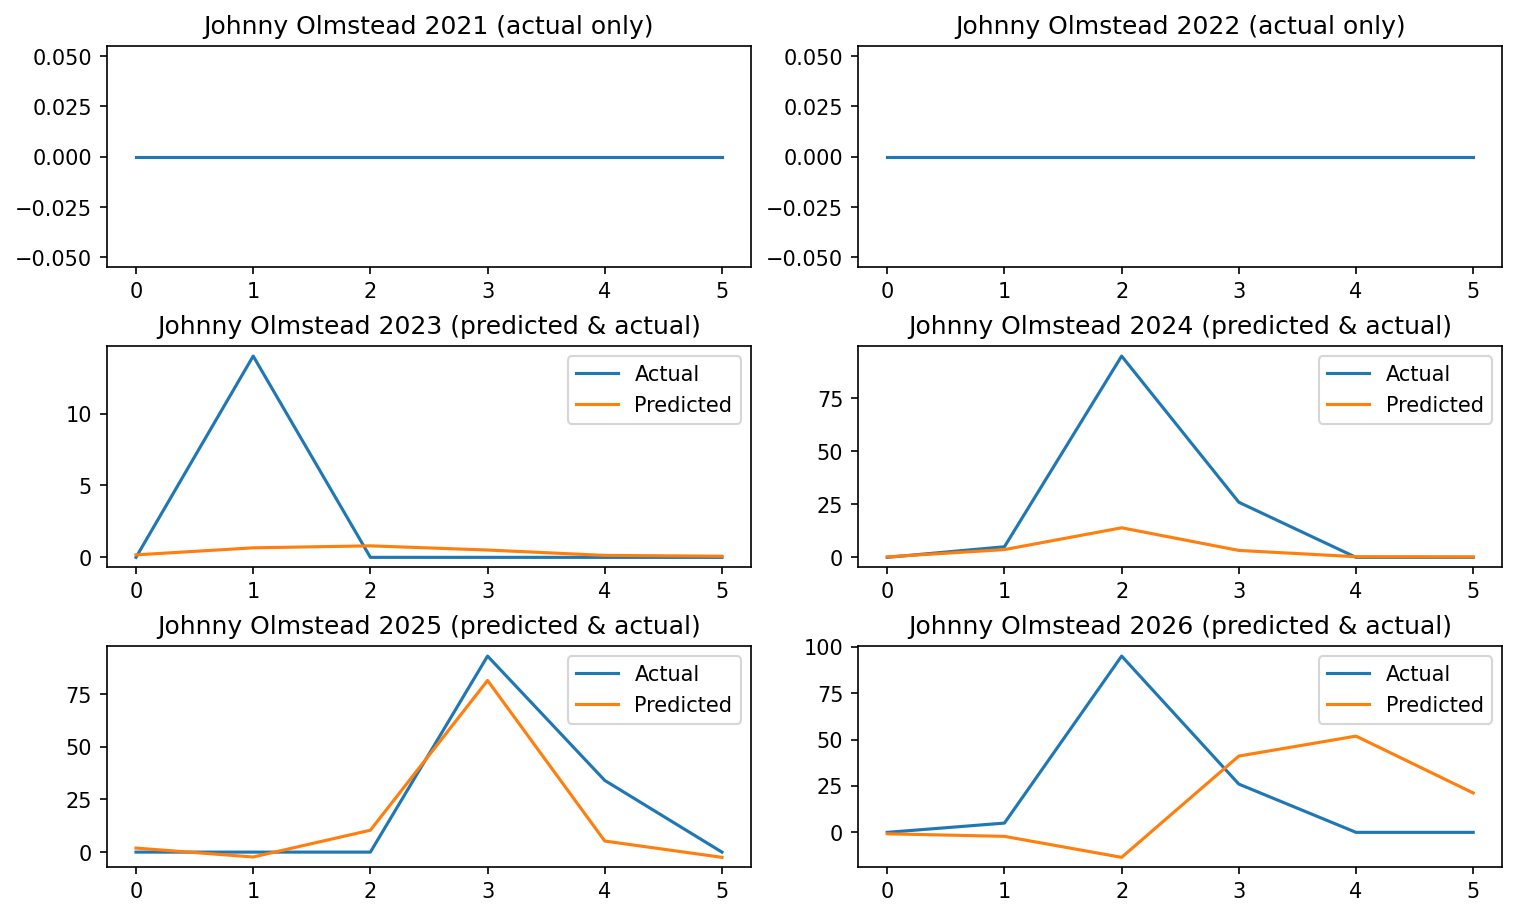

In [19]:
test_random(nbeats_pt, intl_league_rosters)

### Pacific Coast League random visualizer

In [20]:
pcl_team_ids = get_league_team_ids(teams, pcl_league_id)
pcl_rosters = []
for team in pcl_team_ids:
    team_roster = get_team_roster_hitter_ids(team)
    pcl_rosters.extend(team_roster)



Fetching list of teams in league 112:
----------------------------------------------
Round Rock Express
Sacramento River Cats
Oklahoma City Comets
Reno Aces
Albuquerque Isotopes
Las Vegas Aviators
Tacoma Rainiers
Salt Lake Bees
El Paso Chihuahuas
Sugar Land Space Cowboys
701648  Aaron Zavala {'code': '7', 'name': 'Outfielder', 'type': 'Outfielder', 'abbreviation': 'LF'}
666194  Cooper Johnson {'code': '2', 'name': 'Catcher', 'type': 'Catcher', 'abbreviation': 'C'}
660636  Diego Castillo {'code': '6', 'name': 'Shortstop', 'type': 'Infielder', 'abbreviation': 'SS'}
669413  Frainyer Chavez {'code': '4', 'name': 'Second Base', 'type': 'Infielder', 'abbreviation': '2B'}
822966  John Taylor {'code': '5', 'name': 'Third Base', 'type': 'Infielder', 'abbreviation': '3B'}
683149  Julian Brock {'code': '2', 'name': 'Catcher', 'type': 'Catcher', 'abbreviation': 'C'}
677601  Keyber Rodriguez {'code': '6', 'name': 'Shortstop', 'type': 'Infielder', 'abbreviation': 'SS'}
678636  Orlando Martinez {'cod

Chosen player is: Omar Martinez
Fetching seasonal logs (approx. 15 seconds)...
His actual seasonal vectors were:
2021: [49, 0, 0, 0, 0, 0]
2022: [0, 0, 0, 0, 0, 0]
2023: [0, 105, 0, 0, 0, 0]
2024: [0, 0, 104, 0, 0, 0]
2025: [0, 0, 57, 24, 23, 0]
2026: [0, 0, 0, 0, 71, 5]
Predicted seasons are:
2023: tensor([ 0.6305, 11.3836, 12.8091,  4.7185,  4.9561,  5.2072],
       grad_fn=<AddBackward0>)
2024: tensor([ 1.2938, 24.4663, 99.2161, 23.0447,  2.4075,  1.4363],
       grad_fn=<AddBackward0>)
2025: tensor([ 1.6793, -3.0875, 12.1156, 90.1331,  2.9891, -0.5837],
       grad_fn=<AddBackward0>)
2026: tensor([ 0.7406, -1.3469,  0.8252, 59.0256, 22.6308,  7.0709],
       grad_fn=<AddBackward0>)


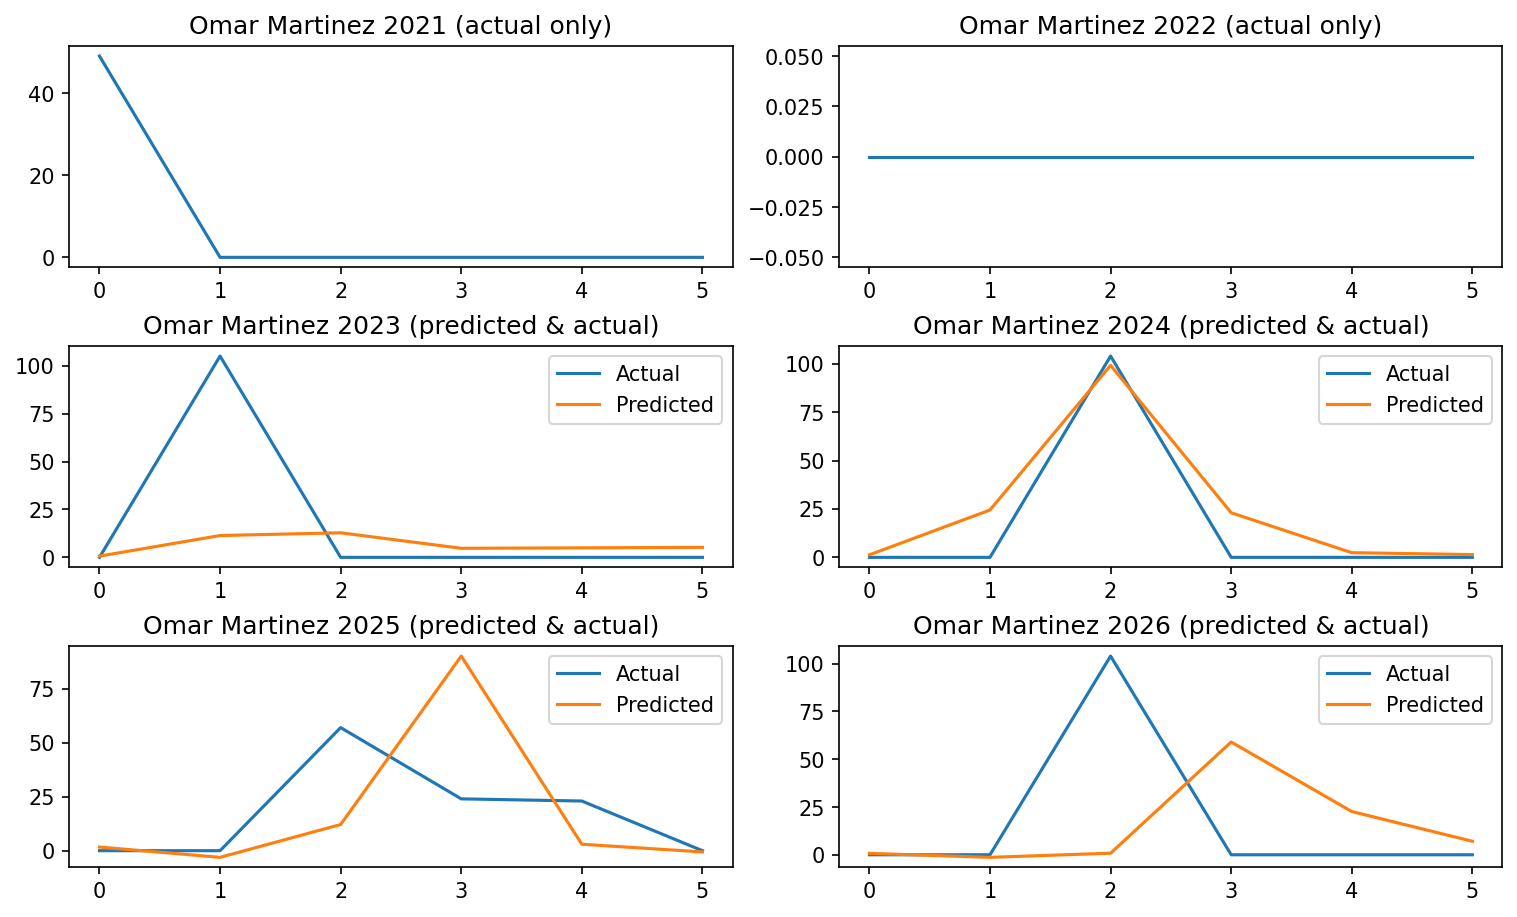

In [21]:
test_random(nbeats_pt, pcl_rosters)